## Eksperimen V2 — LightGBM ATL 2024 (Pengembangan Internal)

In [11]:
from pathlib import Path
import sys, json, hashlib, platform, warnings
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score)
from lightgbm import LGBMClassifier
import lightgbm, sklearn
import optuna
import joblib

SEED_V2 = 42
N_TRIALS_V2 = 20  # default: 20 per skenario; boleh dinaikkan SEBELUM eksperimen dijalankan
N_THREADS_V2 = 4
WINDOWS_V2 = (7, 14, 30)
SMOOTHING_K_V2 = 20.0  # ditetapkan sebelum optimasi
CV_MONTHS_V2 = (5, 6, 7, 8)

WINDOWS_PATH = Path(r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi")
PROJECT_ROOT_V2 = WINDOWS_PATH if WINDOWS_PATH.is_dir() else Path.cwd()
OUTPUT_V2 = PROJECT_ROOT_V2 / "output_eksperimen_v2_2024"
TABLE_V2 = OUTPUT_V2 / "Tabel Data"
MODEL_V2 = OUTPUT_V2 / "Model Eksploratif"
TRIAL_V2 = OUTPUT_V2 / "Optuna"
for folder in (OUTPUT_V2, TABLE_V2, MODEL_V2, TRIAL_V2):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1400)

print("Eksperimen V2 | Hanya periode pengembangan Januari–Agustus 2024")
print("Folder:", OUTPUT_V2.resolve())
print("Versi LightGBM / Optuna / Pandas:", lightgbm.__version__, optuna.__version__, pd.__version__)

Eksperimen V2 | Hanya periode pengembangan Januari–Agustus 2024
Folder: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024
Versi LightGBM / Optuna / Pandas: 4.7.0 5.0.0 3.0.3


### Baca hanya observasi pengembangan Januari–Agustus
Pemilahan dilakukan per chunk saat membaca, sehingga catatan September–Desember tidak diikutkan ke data kerja. Kolom target dan atribut aktual digunakan semata untuk membuat label historis, bukan sebagai prediktor.

In [17]:
# Pilih file dataset ATL 2024. Gunakan lokasi notebook jika tersedia.
CANDIDATE_DATA_V2 = [
    Path("flight_data_2024_origin_ATL(1).xls"),
    Path("flight_data_2024_origin_ATL.xls"),
    Path("flight_data_2024_origin_ATL.csv"),
    Path("/mnt/data/flight_data_2024_origin_ATL(1).xls"),
]
DATA_PATH_V2 = next((p for p in CANDIDATE_DATA_V2 if p.is_file()), None)
if DATA_PATH_V2 is None:
    # Pada Windows, pilih lokasi file secara manual melalui File Explorer.
    try:
        from tkinter import Tk, filedialog
        root_v2 = Tk()
        root_v2.withdraw()
        root_v2.attributes("-topmost", True)
        chosen_v2 = filedialog.askopenfilename(
            parent=root_v2,
            title="Pilih file dataset ATL 2024",
            filetypes=[("Dataset ATL (.xls/.csv)", "*.xls *.csv"), ("Semua file", "*.*")],
        )
        root_v2.destroy()
        DATA_PATH_V2 = Path(chosen_v2) if chosen_v2 else None
    except Exception as exc:
        raise FileNotFoundError(
            "Dataset tidak ditemukan. Simpan dataset di folder notebook atau "
            "isi DATA_PATH_V2 = Path(r'C:\\lokasi\\dataset.xls') secara manual."
        ) from exc
if DATA_PATH_V2 is None or not DATA_PATH_V2.is_file():
    raise FileNotFoundError("Dataset ATL 2024 belum dipilih atau file tidak ada.")

SOURCE_COLS_V2 = [
    "fl_date", "cancelled", "dep_delay", "month", "day_of_month",
    "day_of_week", "crs_dep_time", "op_unique_carrier",
    "op_carrier_fl_num", "dest", "distance", "crs_elapsed_time"
]

# Membaca dataset langsung ke variabel dev_v2 (file .xls ini berformat CSV).
dev_v2 = pd.read_csv(DATA_PATH_V2, usecols=SOURCE_COLS_V2, low_memory=False)

# Batasi observasi ke periode pengembangan, tanpa memakai Sep–Des untuk evaluasi V2.
dev_v2["fl_date"] = pd.to_datetime(dev_v2["fl_date"], format="%Y-%m-%d", errors="raise")
dev_v2 = dev_v2.loc[
    dev_v2["fl_date"].between("2024-01-01", "2024-08-31")
].copy()

dev_v2["cancelled"] = pd.to_numeric(dev_v2["cancelled"], errors="raise")
dev_v2["dep_delay"] = pd.to_numeric(dev_v2["dep_delay"], errors="coerce")
dev_v2 = dev_v2.loc[
    dev_v2["cancelled"].eq(0) & dev_v2["dep_delay"].notna()
    & np.isfinite(dev_v2["dep_delay"])
].copy()
dev_v2["target_delay"] = dev_v2["dep_delay"].ge(15).astype("int8")
dev_v2 = dev_v2.sort_values(["fl_date", "crs_dep_time"], kind="stable").reset_index(drop=True)
dev_v2["flight_uid"] = np.arange(len(dev_v2), dtype=np.int64)

assert len(dev_v2) == 223_971, f"Jumlah training Jan–Aug tidak cocok dengan V1: {len(dev_v2):,}"
assert dev_v2["fl_date"].between("2024-01-01", "2024-08-31").all()
assert dev_v2["target_delay"].isin([0, 1]).all()
assert not ("2024-09-01" <= dev_v2["fl_date"].max().strftime("%Y-%m-%d"))

# Fingerprint dataset pengembangan untuk audit dan konsistensi konfigurasi trial.
hash_columns_v2 = [
    "fl_date", "crs_dep_time", "dep_delay", "op_unique_carrier",
    "dest", "op_carrier_fl_num", "distance", "crs_elapsed_time"
]
DATA_FINGERPRINT_V2 = hashlib.sha256(
    pd.util.hash_pandas_object(dev_v2[hash_columns_v2], index=True)
    .to_numpy(dtype="uint64").tobytes()
).hexdigest()
print("Dataset ditemukan:", DATA_PATH_V2)
print("Fingerprint dataset pengembangan:", DATA_FINGERPRINT_V2[:16])
print(f"Dataset V2: {len(dev_v2):,} observasi; Delayed: {int(dev_v2['target_delay'].sum()):,}; "
      f"proporsi: {dev_v2['target_delay'].mean():.4%}")
print("Periode:", dev_v2["fl_date"].min().date(), "s.d.", dev_v2["fl_date"].max().date())


Dataset ditemukan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\flight_data_2024_origin_ATL.xls
Fingerprint dataset pengembangan: 44b165c21d1bc5d9
Dataset V2: 223,971 observasi; Delayed: 48,671; proporsi: 21.7309%
Periode: 2024-01-01 s.d. 2024-08-31


### Fitur jadwal dan batas ketersediaan informasi T−2h
Kombinasi op_unique_carrier dan op_carrier_fl_num digunakan sebagai ID layanan terjadwal (categorical, bukan angka kontinu). scheduled_dep_minute menambah resolusi waktu tanpa menggunakan realisasi keberangkatan.

In [18]:
raw_hhmm_v2 = pd.to_numeric(dev_v2["crs_dep_time"], errors="raise")
assert raw_hhmm_v2.notna().all() and raw_hhmm_v2.mod(1).eq(0).all()
hr_v2 = (raw_hhmm_v2 // 100).astype("int16")
minute_v2 = (raw_hhmm_v2 % 100).astype("int16")
assert hr_v2.between(0, 23).all() and minute_v2.between(0, 59).all()

dev_v2["scheduled_dep_hour"] = hr_v2
dev_v2["scheduled_dep_minute"] = minute_v2
dev_v2["scheduled_dep_datetime"] = (dev_v2["fl_date"].dt.normalize()
    + pd.to_timedelta(hr_v2, unit="h") + pd.to_timedelta(minute_v2, unit="m"))
dev_v2["t_cutoff"] = dev_v2["scheduled_dep_datetime"] - pd.Timedelta(hours=2)
dev_v2["t_gate_proxy"] = (dev_v2["scheduled_dep_datetime"]
                          + pd.to_timedelta(dev_v2["dep_delay"], unit="m"))

for numeric_col_v2 in ["month", "day_of_month", "day_of_week", "distance", "crs_elapsed_time"]:
    dev_v2[numeric_col_v2] = pd.to_numeric(dev_v2[numeric_col_v2], errors="raise")
assert dev_v2["day_of_month"].between(1,31).all()
assert dev_v2["distance"].gt(0).all() and dev_v2["crs_elapsed_time"].gt(0).all()
num_flight_v2 = pd.to_numeric(dev_v2["op_carrier_fl_num"], errors="raise")
assert num_flight_v2.notna().all() and num_flight_v2.mod(1).eq(0).all()
dev_v2["flight_service_id"] = (dev_v2["op_unique_carrier"].astype(str) + ":"
    + num_flight_v2.astype("int64").astype(str))
assert dev_v2[["scheduled_dep_datetime", "t_cutoff", "t_gate_proxy"]].notna().all().all()
assert dev_v2[["op_unique_carrier", "dest", "flight_service_id"]].notna().all().all()

BASE_V2 = ["month", "day_of_week", "scheduled_dep_hour", "op_unique_carrier",
           "dest", "distance", "crs_elapsed_time", "day_of_month",
           "scheduled_dep_minute", "flight_service_id"]
CAT_V2 = ["op_unique_carrier", "dest", "flight_service_id"]
GROUPS_V2 = [
    ("carrier", ["op_unique_carrier"]),
    ("dest", ["dest"]),
    ("carrier_dest", ["op_unique_carrier", "dest"]),
]
HISTORY_V2 = [f"hist_{kind}_{metric}_{days}d" for kind, _ in GROUPS_V2
              for days in WINDOWS_V2 for metric in ("rate", "log_count")]
ENHANCED_V2 = BASE_V2 + HISTORY_V2
FORBIDDEN_V2 = {"dep_delay", "target_delay", "cancelled", "t_gate_proxy",
                "t_cutoff", "scheduled_dep_datetime", "fl_date", "flight_uid",
                "dep_time", "arr_delay", "taxi_out", "wheels_off", "arr_time"}
assert len(BASE_V2) == 10 and len(ENHANCED_V2) == 28
assert FORBIDDEN_V2.isdisjoint(ENHANCED_V2)
print(f"Fitur V2: Baseline={len(BASE_V2)}, Enhanced={len(ENHANCED_V2)}")
print("Daftar Enhanced:", ", ".join(ENHANCED_V2))

Fitur V2: Baseline=10, Enhanced=28
Daftar Enhanced: month, day_of_week, scheduled_dep_hour, op_unique_carrier, dest, distance, crs_elapsed_time, day_of_month, scheduled_dep_minute, flight_service_id, hist_carrier_rate_7d, hist_carrier_log_count_7d, hist_carrier_rate_14d, hist_carrier_log_count_14d, hist_carrier_rate_30d, hist_carrier_log_count_30d, hist_dest_rate_7d, hist_dest_log_count_7d, hist_dest_rate_14d, hist_dest_log_count_14d, hist_dest_rate_30d, hist_dest_log_count_30d, hist_carrier_dest_rate_7d, hist_carrier_dest_log_count_7d, hist_carrier_dest_rate_14d, hist_carrier_dest_log_count_14d, hist_carrier_dest_rate_30d, hist_carrier_dest_log_count_30d


### Definisi empat fold temporal internal
Folds ditentukan sebelum melihat hasil AP. Periode awal yang digunakan untuk training minimal Januari–April 2024.

In [19]:
FOLDS_V2 = []
for val_month_v2 in CV_MONTHS_V2:
    train_indices_v2 = dev_v2.index[dev_v2["month"].lt(val_month_v2)].to_numpy()
    val_indices_v2 = dev_v2.index[dev_v2["month"].eq(val_month_v2)].to_numpy()
    assert len(train_indices_v2)>0 and len(val_indices_v2)>0
    assert dev_v2.loc[train_indices_v2, "fl_date"].max() < dev_v2.loc[val_indices_v2, "fl_date"].min()
    FOLDS_V2.append({"month": val_month_v2, "train_idx": train_indices_v2,
                     "val_idx": val_indices_v2})

fold_overview_v2 = pd.DataFrame([{
    "Fold": i + 1, "Training": "Januari–" + str(pd.Timestamp(2024, f["month"] - 1, 1).strftime("%B")),
    "Validation": pd.Timestamp(2024, f["month"], 1).strftime("%B"),
    "n Training": len(f["train_idx"]), "n Validation": len(f["val_idx"])
} for i, f in enumerate(FOLDS_V2)])
print("Tabel Eksperimen V2.1 Pembagian Empat Fold Temporal Internal")
display(fold_overview_v2.style.set_properties(**{"white-space":"normal", "overflow-wrap":"break-word"}))
assert len(set(np.concatenate([f["val_idx"] for f in FOLDS_V2]))) == sum(len(f["val_idx"]) for f in FOLDS_V2)
print("Audit fold: tidak saling tumpang tindih dan seluruh training mendahului validation.")

Tabel Eksperimen V2.1 Pembagian Empat Fold Temporal Internal


,Fold,Training,Validation,n Training,n Validation
0,1,Januari–April,May,107587,29697
1,2,Januari–May,June,137284,29218
2,3,Januari–June,July,166502,28294
3,4,Januari–July,August,194796,29175


Audit fold: tidak saling tumpang tindih dan seluruh training mendahului validation.


### Fungsi statistik historis rolling yang benar-benar kausal
Untuk setiap fold:
- Label sumber hanya berasal dari training fold.
- Label baru dianggap tersedia pada t_gate_proxy = scheduled_dep_datetime + dep_delay menit, sesuai asumsi V1.
- Riwayat jendela adalah [t_cutoff − window, t_cutoff).
- merge_asof(..., allow_exact_matches=False) menerapkan batas ketat; penerbangan target dikecualikan secara eksplisit.
- rate menggunakan smoothing terhadap proporsi global yang telah tersedia sebelum cutoff (bukan rerata global seluruh training); log_count = log1p(n_historis) memberikan dukungan ukuran sampel.
- Baris validation tidak menyumbangkan label ke fitur validation lainnya, meskipun tanggalnya lebih dahulu.
Fungsi menerima sumber dan query terpisah agar audit fold tidak bergantung pada urutan eksekusi notebook.

In [20]:
def _asof_cumsum_v2(events, queries, by_cols, when):
    """Jumlah dan label positif kumulatif ketika t_gate_proxy < when, menurut grup."""
    ev_cols = ["t_gate_proxy", "flight_uid", "target_delay", *by_cols]
    e = events[ev_cols].sort_values("t_gate_proxy", kind="mergesort").copy()
    # Pandas dapat memakai resolusi waktu us untuk sumber dan ns untuk lookup.
    # merge_asof mewajibkan kedua kunci waktu dengan dtype IDENTIK.
    e["t_gate_proxy"] = pd.to_datetime(e["t_gate_proxy"]).astype("datetime64[ns]")
    if by_cols:
        grouped = e.groupby(by_cols, sort=False, observed=True)
        e["cum_n"] = (grouped.cumcount() + 1).astype("int32")
        e["cum_pos"] = grouped["target_delay"].cumsum().astype("int32")
    else:
        e["cum_n"] = np.arange(1, len(e) + 1, dtype="int32")
        e["cum_pos"] = e["target_delay"].cumsum().astype("int32")
    e = e[["t_gate_proxy", "cum_n", "cum_pos", *by_cols]]
    q = queries[["flight_uid", *by_cols]].copy()
    q["lookup_time"] = pd.to_datetime(when).to_numpy(dtype="datetime64[ns]")
    q = q.sort_values("lookup_time", kind="mergesort")
    matched = pd.merge_asof(q, e, left_on="lookup_time", right_on="t_gate_proxy",
                            by=by_cols if by_cols else None, direction="backward",
                            allow_exact_matches=False)
    matched = matched.set_index("flight_uid").reindex(queries["flight_uid"])
    return (matched["cum_n"].fillna(0).to_numpy(dtype=np.int64),
            matched["cum_pos"].fillna(0).to_numpy(dtype=np.int64))


def build_roll_features_v2(source_train, query_rows):
    """Bentuk 18 fitur historis; tidak pernah mengambil label query validation."""
    assert len(source_train)>0 and len(query_rows)>0
    assert source_train["flight_uid"].is_unique and query_rows["flight_uid"].is_unique
    assert source_train["t_gate_proxy"].notna().all() and query_rows["t_cutoff"].notna().all()
    assert source_train["target_delay"].isin([0,1]).all()
    q = query_rows[["flight_uid", "t_cutoff", "op_unique_carrier", "dest"]].copy()
    # Self-exclusion memakai metadata sumber saja. Tidak memakai dep_delay/query label validation.
    source_uid = source_train.set_index("flight_uid")[["t_gate_proxy", "target_delay"]]
    own = source_uid.reindex(q["flight_uid"])
    own_gate = own["t_gate_proxy"].to_numpy(dtype="datetime64[ns]")
    own_target = own["target_delay"].fillna(0).to_numpy(dtype=np.int64)
    cutoff = q["t_cutoff"].to_numpy(dtype="datetime64[ns]")
    own_available = np.isnat(own_gate) == False
    own_available &= own_gate < cutoff

    global_n, global_pos = _asof_cumsum_v2(source_train, q, [], q["t_cutoff"])
    global_n -= own_available.astype("int64")
    global_pos -= own_available.astype("int64") * own_target
    assert (global_n >= 0).all() and (global_pos <= global_n).all()
    global_prior = np.divide(global_pos, global_n,
                             out=np.full(len(q), np.nan, dtype=np.float64), where=global_n>0)
    result = pd.DataFrame(index=query_rows.index)

    for kind, group_cols in GROUPS_V2:
        top_n, top_pos = _asof_cumsum_v2(source_train, q, group_cols, q["t_cutoff"])
        for days in WINDOWS_V2:
            lower = q["t_cutoff"] - pd.Timedelta(days=days)
            bottom_n, bottom_pos = _asof_cumsum_v2(source_train, q, group_cols, lower)
            n_obs = top_n - bottom_n
            n_pos = top_pos - bottom_pos
            # Hanya sumber yang sama dengan target perlu dikurangi bila berada dalam jendela.
            self_in_window = own_available & (own_gate >= lower.to_numpy(dtype="datetime64[ns]"))
            n_obs -= self_in_window.astype(np.int64)
            n_pos -= self_in_window.astype(np.int64) * own_target
            assert (n_obs >= 0).all() and (n_pos >= 0).all() and (n_pos <= n_obs).all()
            smoothed = (n_pos + SMOOTHING_K_V2 * global_prior) / (n_obs + SMOOTHING_K_V2)
            smoothed[np.isnan(global_prior)] = np.nan
            rate_col = f"hist_{kind}_rate_{days}d"
            count_col = f"hist_{kind}_log_count_{days}d"
            result[rate_col] = pd.Series(smoothed, index=result.index, dtype="float32")
            result[count_col] = pd.Series(np.log1p(n_obs), index=result.index, dtype="float32")
            assert result[rate_col].dropna().between(0,1).all()
    assert result.columns.tolist() == HISTORY_V2
    return result

print("Fungsi historis kausal V2 telah didefinisikan. Belum ada pelatihan model.")

Fungsi historis kausal V2 telah didefinisikan. Belum ada pelatihan model.


### Audit independen fungsi historis dengan subset data riil
Subset awal hanya untuk uji fungsi, bukan untuk menghasilkan metrik penelitian. Pemeriksaan melakukan penghitungan manual untuk beberapa cutoff, tanpa melihat data testing.

In [21]:
sample_src_v2 = dev_v2.iloc[:1_500].copy()
sample_query_v2 = sample_src_v2.iloc[:25].copy()
sample_hist_v2 = build_roll_features_v2(sample_src_v2, sample_query_v2)
for idx_v2 in [0, 4, 12, 24]:
    row_v2 = sample_query_v2.iloc[idx_v2]
    for kind_v2, keys_v2 in GROUPS_V2:
        for w_v2 in WINDOWS_V2:
            valid_v2 = (sample_src_v2["t_gate_proxy"].lt(row_v2["t_cutoff"])
                        & sample_src_v2["t_gate_proxy"].ge(row_v2["t_cutoff"] - pd.Timedelta(days=w_v2))
                        & sample_src_v2["flight_uid"].ne(row_v2["flight_uid"]))
            for key_v2 in keys_v2:
                valid_v2 &= sample_src_v2[key_v2].eq(row_v2[key_v2])
            exact_count_v2 = int(valid_v2.sum())
            stored_count_v2 = np.expm1(float(sample_hist_v2.loc[row_v2.name, f"hist_{kind_v2}_log_count_{w_v2}d"]))
            assert np.isclose(stored_count_v2, exact_count_v2, atol=1e-4), (kind_v2, w_v2, idx_v2)
print("Uji hitung manual jendela, cutoff ketat, dan pengecualian diri: LULUS (subset sumber riil).")

Uji hitung manual jendela, cutoff ketat, dan pengecualian diri: LULUS (subset sumber riil).


### Pembentukan matriks V2 per fold dan audit kategori
Sel ini paling berat sebelum optimasi karena menghitung rolling historis untuk setiap fold. Kamus kategorikal disusun hanya dari training fold. Jika kategori belum pernah muncul pada training fold, nilainya menjadi NaN pada validation fold (ditangani LightGBM).

In [22]:
def matrices_for_fold_v2(source_train, query_val):
    assert source_train["fl_date"].max() < query_val["fl_date"].min()
    train_hist = build_roll_features_v2(source_train, source_train)
    val_hist = build_roll_features_v2(source_train, query_val)
    def make_x(data, hist, features):
        base = data[BASE_V2].copy()
        return base if features == BASE_V2 else pd.concat([base, hist], axis=1)
    x_train_base = make_x(source_train, train_hist, BASE_V2)
    x_val_base = make_x(query_val, val_hist, BASE_V2)
    x_train_plus = make_x(source_train, train_hist, ENHANCED_V2)
    x_val_plus = make_x(query_val, val_hist, ENHANCED_V2)
    for col in CAT_V2:
        vocabulary = sorted(source_train[col].astype(str).unique().tolist())
        dtype = pd.CategoricalDtype(vocabulary, ordered=False)
        for x in (x_train_base, x_val_base, x_train_plus, x_val_plus):
            x[col] = x[col].astype(dtype)
        assert x_train_base[col].notna().all()
    assert x_train_base.equals(x_train_plus[BASE_V2])
    assert x_val_base.equals(x_val_plus[BASE_V2])
    assert x_train_plus.index.equals(source_train.index)
    assert x_val_plus.index.equals(query_val.index)
    assert FORBIDDEN_V2.isdisjoint(x_train_plus.columns)
    assert FORBIDDEN_V2.isdisjoint(x_val_plus.columns)
    for x in (x_train_plus, x_val_plus):
        for column in x.columns:
            if column not in CAT_V2:
                assert np.isfinite(x[column].dropna().to_numpy(dtype=float)).all()
    return {"X_train_base": x_train_base, "X_val_base": x_val_base,
            "X_train_enh": x_train_plus, "X_val_enh": x_val_plus,
            "y_train": source_train["target_delay"].copy(),
            "y_val": query_val["target_delay"].copy(),
            "train_source": source_train, "val_source": query_val}

FOLD_CACHE_V2 = []
for fold_num_v2, fold_def_v2 in enumerate(FOLDS_V2, start=1):
    src_v2 = dev_v2.loc[fold_def_v2["train_idx"]]
    qry_v2 = dev_v2.loc[fold_def_v2["val_idx"]]
    matrices_v2 = matrices_for_fold_v2(src_v2, qry_v2)
    matrices_v2["fold_number"] = fold_num_v2
    matrices_v2["val_month"] = fold_def_v2["month"]
    FOLD_CACHE_V2.append(matrices_v2)
    print(f"Fold {fold_num_v2}: train={len(src_v2):,}; validation={len(qry_v2):,}; "
          f"fitur base/enh={matrices_v2['X_train_base'].shape[1]}/{matrices_v2['X_train_enh'].shape[1]}")
assert len(FOLD_CACHE_V2) == 4
print("Keempat fold selesai dibentuk; September–Desember tidak diakses.")

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not i

Fold 1: train=107,587; validation=29,697; fitur base/enh=10/28


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not i

Fold 2: train=137,284; validation=29,218; fitur base/enh=10/28


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)


Fold 3: train=166,502; validation=28,294; fitur base/enh=10/28
Fold 4: train=194,796; validation=29,175; fitur base/enh=10/28
Keempat fold selesai dibentuk; September–Desember tidak diakses.


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_28684\1670269270.py:16: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  x[col] = x[col].astype(dtype)


### Audit ketat kebocoran temporal pada fold
Pemeriksaan tambahan menghitung ulang histori validasi langsung dari label sumber training untuk beberapa baris yang dipilih deterministik. Validasi tidak dijadikan sumber histori pada fold yang sama.

In [23]:
for fold_v2 in FOLD_CACHE_V2:
    source = fold_v2["train_source"]
    query = fold_v2["val_source"]
    sample_rows = query.iloc[np.linspace(0, len(query)-1, 4, dtype=int)]
    for idx, item in sample_rows.iterrows():
        for kind, group_cols in GROUPS_V2:
            for days in WINDOWS_V2:
                eligible = source["t_gate_proxy"].lt(item["t_cutoff"]) & source["t_gate_proxy"].ge(item["t_cutoff"] - pd.Timedelta(days=days))
                for key in group_cols:
                    eligible &= source[key].eq(item[key])
                actual = int(eligible.sum())
                encoded = np.expm1(float(fold_v2["X_val_enh"].loc[idx, f"hist_{kind}_log_count_{days}d"]))
                assert np.isclose(encoded, actual, atol=1e-3), (fold_v2["fold_number"], idx, kind, days)
        assert idx not in source.index
print("Audit independen 4 fold × 4 observasi × 9 kombinasi: LULUS.")

Audit independen 4 fold × 4 observasi × 9 kombinasi: LULUS.


### Ruang pencarian Optuna yang sama untuk kedua skenario
Objektif = rerata AP per fold (tanpa integrasi PR trapezoidal). Tiap trial melatih model ulang di setiap fold, namun tidak mengakses partisi September–Desember. Budget awal 20 trial per skenario untuk menghindari penggunaan komputasi berlebihan; setelah eksekusi awal, jangan meningkatkan budget secara selektif hanya untuk skenario yang tertinggal tanpa mencatat desain eksperimen baru.

In [24]:
FIXED_LGBM_V2 = dict(
    objective="binary", boosting_type="gbdt", random_state=SEED_V2,
    n_jobs=N_THREADS_V2, verbosity=-1, deterministic=True,
    force_col_wise=True, device_type="cpu"
)

def sample_params_v2(trial):
    depth = trial.suggest_int("max_depth", 4, 10)
    return dict(
        max_depth=depth,
        num_leaves=trial.suggest_int("num_leaves", 15, min(127, 2**depth)),
        learning_rate=trial.suggest_float("learning_rate", 0.02, 0.15, log=True),
        n_estimators=trial.suggest_int("n_estimators", 200, 800, step=100),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 150, step=10),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 15, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-4, 2, log=True),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.75, 1.0),
        subsample=trial.suggest_float("subsample", 0.75, 1.0),
        subsample_freq=1,
        cat_smooth=trial.suggest_int("cat_smooth", 5, 50, step=5)
    )

def cv_ap_v2(params, scenario):
    is_enh = scenario == "Enhanced"
    scores = []
    for fold in FOLD_CACHE_V2:
        xt = fold["X_train_enh" if is_enh else "X_train_base"]
        xv = fold["X_val_enh" if is_enh else "X_val_base"]
        model = LGBMClassifier(**FIXED_LGBM_V2, **params)
        model.fit(xt, fold["y_train"], categorical_feature=CAT_V2)
        proba = model.predict_proba(xv, validate_features=True)[:, 1]
        assert len(proba) == len(fold["y_val"]) and np.isfinite(proba).all()
        scores.append(float(average_precision_score(fold["y_val"], proba)))
    return float(np.mean(scores)), scores

print("Siap mencari hiperparameter; N_TRIALS_V2 =", N_TRIALS_V2)
print("Tidak ada pemanggilan parameter tuning pada data testing.")

Siap mencari hiperparameter; N_TRIALS_V2 = 20
Tidak ada pemanggilan parameter tuning pada data testing.


### Optimasi dua skenario dengan penyimpanan riwayat
SQLite memungkinkan kelanjutan studi apabila kernel/restart laptop terputus. Trial yang terputus saat reboot dicatat sebagai FAIL, dan kekurangan trial COMPLETE dijalankan ulang. Jangan menjalankan optimasi yang sama dari dua notebook/proses secara bersamaan. Jejak sampler TPE setelah restart bisa berbeda dari satu eksekusi tanpa jeda, meskipun seluruh parameter dan seed dicatat. Konfigurasi studi dikunci; jangan ganti jumlah fold/fitur/ruang pencarian saat melanjutkan database yang sama. Jika perlu desain baru, gunakan folder atau nama studi baru.

Estimasi proses: 2 skenario × 20 trial × 4 fold = 160 pelatihan, sehingga sel ini dapat memerlukan waktu cukup lama di laptop.

In [25]:
SEARCH_SIGNATURE_V2 = hashlib.sha256(json.dumps({
    "fold_months": CV_MONTHS_V2, "windows": WINDOWS_V2, "smooth_k": SMOOTHING_K_V2,
    "baseline_features": BASE_V2, "enhanced_features": ENHANCED_V2,
    "fixed_params": FIXED_LGBM_V2, "trial_budget": N_TRIALS_V2,
    "search_space_version": "v2_ap_fold_mean_regularized_2024_v1",
    "data_rows": len(dev_v2), "data_last_date": str(dev_v2['fl_date'].max().date()),
    "data_fingerprint_sha256": DATA_FINGERPRINT_V2,
}, sort_keys=True).encode()).hexdigest()


def optimize_scenario_v2(scenario):
    assert scenario in ("Baseline", "Enhanced")
    uri = "sqlite:///" + (TRIAL_V2 / f"Optuna_V2_{scenario}.sqlite3").resolve().as_posix()
    study = optuna.create_study(
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED_V2),
        storage=uri, study_name=f"ATL_2024_V2_{scenario}", load_if_exists=True
    )
    signature = study.user_attrs.get("experiment_signature")
    if signature is not None and signature != SEARCH_SIGNATURE_V2:
        raise RuntimeError(f"Konfigurasi eksperimen {scenario} berubah. Buat studi baru, jangan lanjutkan SQLite lama.")
    if signature is None and len(study.trials)>0:
        raise RuntimeError("SQLite memiliki trial tanpa signature; tidak aman untuk dilanjutkan.")
    study.set_user_attr("experiment_signature", SEARCH_SIGNATURE_V2)
    def objective(trial):
        params = sample_params_v2(trial)
        score, fold_scores = cv_ap_v2(params, scenario)
        for i, val in enumerate(fold_scores, 1):
            trial.set_user_attr(f"ap_fold_{i}", val)
        return score
    # Jika reboot memutus satu trial RUNNING, tandai gagal dan ulangi hanya trial itu.
    # Hanya aman bila tidak ada proses optimasi lain yang masih berjalan pada database ini.
    for old_trial in study.trials:
        if old_trial.state == optuna.trial.TrialState.RUNNING:
            study.tell(old_trial.number, state=optuna.trial.TrialState.FAIL)
            print(f"Trial {old_trial.number} dari {scenario} terputus; ditandai FAIL untuk audit.")
    complete = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    failed = sum(t.state == optuna.trial.TrialState.FAIL for t in study.trials)
    if complete > N_TRIALS_V2:
        raise RuntimeError("Trial COMPLETE melebihi budget eksperimen yang dikunci.")
    if failed:
        print(f"Catatan {scenario}: {failed} trial FAIL tersimpan; budget berlaku untuk trial COMPLETE.")
    if complete < N_TRIALS_V2:
        study.optimize(objective, n_trials=N_TRIALS_V2 - complete, gc_after_trial=True)
    assert sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials) == N_TRIALS_V2
    assert all(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.FAIL)
               for t in study.trials)
    study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))\
        .to_csv(TRIAL_V2 / f"Optuna_V2_{scenario}_Trials.csv", index=False)
    return study

optuna.logging.set_verbosity(optuna.logging.WARNING)
study_baseline_v2 = optimize_scenario_v2("Baseline")
print(f"Baseline V2: AP rerata 4-fold = {study_baseline_v2.best_value:.6f}; "
      f"trial lengkap = {len(study_baseline_v2.trials)}")
study_enhanced_v2 = optimize_scenario_v2("Enhanced")
print(f"Enhanced V2: AP rerata 4-fold = {study_enhanced_v2.best_value:.6f}; "
      f"trial lengkap = {len(study_enhanced_v2.trials)}")

Baseline V2: AP rerata 4-fold = 0.379080; trial lengkap = 20
Enhanced V2: AP rerata 4-fold = 0.386604; trial lengkap = 20


### Evaluasi terpilih pada empat fold (Out-of-Fold)
Menghitung ulang probabilitas pada validasi internal dengan hiperparameter terbaik, lalu membekukan threshold F1 dari seluruh prediksi OOF. Perhitungan threshold menggunakan satu prosedur identik pada kedua skenario. Semua prediksi berasal dari model yang tidak dilatih pada label bulan validasi terkait.

In [29]:
def oof_selected_v2(study, scenario):
    params = dict(study.best_params, subsample_freq=1)
    rows, fold_aps = [], []
    for fold in FOLD_CACHE_V2:
        enh = scenario == "Enhanced"
        xt = fold["X_train_enh" if enh else "X_train_base"]
        xv = fold["X_val_enh" if enh else "X_val_base"]
        model = LGBMClassifier(**FIXED_LGBM_V2, **params)
        model.fit(xt, fold["y_train"], categorical_feature=CAT_V2)
        proba = model.predict_proba(xv, validate_features=True)[:, 1]
        ap = average_precision_score(fold["y_val"], proba)
        fold_aps.append(float(ap))
        rows.append(pd.DataFrame({
            "flight_uid": fold["val_source"]["flight_uid"].to_numpy(),
            "fl_date": fold["val_source"]["fl_date"].to_numpy(),
            "fold": fold["fold_number"], "y_true": fold["y_val"].to_numpy(),
            "y_proba": proba, "scenario": scenario
        }))
    df = pd.concat(rows, ignore_index=True)
    assert df["flight_uid"].is_unique and np.isfinite(df["y_proba"]).all()
    assert np.isclose(float(np.mean(fold_aps)), float(study.best_value), atol=1e-8)
    return df, fold_aps

def threshold_f1_v2(y, prob):
    thresholds = np.arange(1, 1000, dtype=np.float64) / 1000
    order = np.argsort(prob, kind="mergesort")
    sorted_y = np.asarray(y, dtype=np.int64)[order]
    sorted_p = np.asarray(prob, dtype=np.float64)[order]
    pos_suffix = np.r_[np.cumsum(sorted_y[::-1], dtype=np.int64)[::-1], 0]
    ix = np.searchsorted(sorted_p, thresholds, side="left")
    tp = pos_suffix[ix]
    positive_pred = len(y) - ix
    fp = positive_pred - tp
    fn = int(np.sum(y)) - tp
    precision = np.divide(tp, tp + fp, out=np.zeros(999), where=tp + fp > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros(999), where=tp + fn > 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(999), where=precision + recall > 0)
    # Jika seri F1 identik, pilih threshold terbesar secara deterministik.
    best_ix = np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12, rtol=0))[-1]
    return float(thresholds[best_ix]), pd.DataFrame({
        "threshold": thresholds, "precision": precision, "recall": recall, "f1": f1
    })

OOF_V2 = {}
RESULTS_V2 = {}
for scenario, study in [("Baseline", study_baseline_v2), ("Enhanced", study_enhanced_v2)]:
    oof, aps = oof_selected_v2(study, scenario)
    threshold, history = threshold_f1_v2(oof["y_true"].to_numpy(), oof["y_proba"].to_numpy())
    predicted = (oof["y_proba"].to_numpy() >= threshold).astype(int)
    y = oof["y_true"].to_numpy()
    RESULTS_V2[scenario] = dict(
        ap_fold_mean=float(np.mean(aps)), ap_by_fold=aps,
        ap_pooled_oof=float(average_precision_score(y, oof["y_proba"])),
        threshold=threshold, precision=float(precision_score(y, predicted, zero_division=0)),
        recall=float(recall_score(y, predicted, zero_division=0)),
        f1=float(f1_score(y, predicted, zero_division=0)),
        accuracy=float(accuracy_score(y, predicted)),
        accuracy_at_0_5=float(accuracy_score(y, oof["y_proba"] >= 0.5)),
        n_oof=len(oof), best_params=dict(study.best_params, subsample_freq=1)
    )
    OOF_V2[scenario] = oof
    oof.to_csv(OUTPUT_V2 / f"OOF_V2_{scenario}_Jan_Agu.csv", index=False)
    history.to_csv(TRIAL_V2 / f"Threshold_V2_{scenario}_999_Kandidat.csv", index=False)
    print(f"{scenario}: mean AP={np.mean(aps):.6f}; pooled OOF AP="
          f"{RESULTS_V2[scenario]['ap_pooled_oof']:.6f}; "
          f"threshold F1={threshold:.3f}")

assert np.array_equal(OOF_V2["Baseline"]["flight_uid"], OOF_V2["Enhanced"]["flight_uid"])
assert np.array_equal(OOF_V2["Baseline"]["y_true"], OOF_V2["Enhanced"]["y_true"])
print("Audit OOF: label dan identitas observasi kedua skenario sama.")

Baseline: mean AP=0.379080; pooled OOF AP=0.329671; threshold F1=0.149
Enhanced: mean AP=0.386604; pooled OOF AP=0.353547; threshold F1=0.162
Audit OOF: label dan identitas observasi kedua skenario sama.


### Tabel eksperimen V2 dan ekspor HTML untuk Word
Tabel hanya menampilkan hasil validasi internal Januari–Agustus. Nama tabel tidak memakai nomor Bab IV resmi, agar tidak tertukar dengan Tabel 4.8–4.10 V1. Selisih AP ditampilkan dalam poin persentase.

In [27]:
table_v2 = pd.DataFrame([
    {"Metrik": "AP 4-fold (rerata)", "Baseline V2": RESULTS_V2["Baseline"]["ap_fold_mean"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["ap_fold_mean"]},
    {"Metrik": "AP OOF gabungan", "Baseline V2": RESULTS_V2["Baseline"]["ap_pooled_oof"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["ap_pooled_oof"]},
    {"Metrik": "Accuracy pada threshold F1", "Baseline V2": RESULTS_V2["Baseline"]["accuracy"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["accuracy"]},
    {"Metrik": "Precision Delayed", "Baseline V2": RESULTS_V2["Baseline"]["precision"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["precision"]},
    {"Metrik": "Recall Delayed", "Baseline V2": RESULTS_V2["Baseline"]["recall"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["recall"]},
    {"Metrik": "F1 Delayed", "Baseline V2": RESULTS_V2["Baseline"]["f1"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["f1"]},
    {"Metrik": "Threshold F1 terpilih", "Baseline V2": RESULTS_V2["Baseline"]["threshold"],
     "Enhanced V2": RESULTS_V2["Enhanced"]["threshold"]}
])
table_v2["Selisih (pp)"] = (table_v2["Enhanced V2"] - table_v2["Baseline V2"]) * 100
# Selisih threshold bukan metrik persentase, sehingga ditampilkan kosong.
table_v2.loc[table_v2["Metrik"].eq("Threshold F1 terpilih"), "Selisih (pp)"] = np.nan
print("Tabel Eksperimen V2.2 Perbandingan Hasil Validasi Temporal Internal Baseline dan Enhanced")
display(table_v2.style.format({"Baseline V2":"{:.6f}", "Enhanced V2":"{:.6f}",
                              "Selisih (pp)":"{:+.4f}"}, na_rep="—")
        .set_properties(**{"white-space":"normal", "overflow-wrap":"break-word"}))
file_csv_v2 = TABLE_V2 / "Tabel_Eksperimen_V2_2_Validasi_Internal.csv"
file_html_v2 = TABLE_V2 / "Tabel_Eksperimen_V2_2_Validasi_Internal.html"
table_v2.to_csv(file_csv_v2, index=False)
html_style_v2 = """<style>
@page{size:A4 portrait;margin:1.6cm}body{font-family:Arial,sans-serif;font-size:10pt}
h2{font-size:11pt;text-align:center}table{border-collapse:collapse;width:100%;table-layout:fixed}
th,td{border:1px solid #777;padding:5px 6px;overflow-wrap:break-word}
th{background:#efefef}td:not(:first-child){text-align:right}td:first-child{width:39%}
p{font-size:9pt;color:#555}
</style>"""
html_body_v2 = table_v2.to_html(index=False, formatters={
    "Baseline V2": lambda x: f"{x:.6f}", "Enhanced V2": lambda x: f"{x:.6f}",
    "Selisih (pp)": lambda x: "—" if pd.isna(x) else f"{x:+.4f}"}, na_rep="—", border=0)
file_html_v2.write_text("<!DOCTYPE html><html lang='id'><head><meta charset='utf-8'>" + html_style_v2 +
    "</head><body><h2>Tabel Eksperimen V2.2 Perbandingan Hasil Validasi Temporal Internal</h2>" +
    html_body_v2 + "<p>Pengembangan internal Januari–Agustus 2024; bukan hasil testing independen. " +
    "Selisih = Enhanced − Baseline dalam poin persentase; AP 4-fold menjadi metrik utama.</p>" +
    "</body></html>", encoding="utf-8")
assert file_csv_v2.is_file() and file_html_v2.is_file()
print("HTML untuk Word:", file_html_v2.resolve())
print("CSV:", file_csv_v2.resolve())

Tabel Eksperimen V2.2 Perbandingan Hasil Validasi Temporal Internal Baseline dan Enhanced


,Metrik,Baseline V2,Enhanced V2,Selisih (pp)
0,AP 4-fold (rerata),0.379080,0.386604,+0.7524
1,AP OOF gabungan,0.329671,0.353547,+2.3877
2,Accuracy pada threshold F1,0.461361,0.489174,+2.7813
3,Precision Delayed,0.297503,0.304655,+0.7152
4,Recall Delayed,0.806801,0.771957,-3.4844
5,F1 Delayed,0.434710,0.436890,+0.2181
6,Threshold F1 terpilih,0.149000,0.162000,—


HTML untuk Word: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Tabel Data\Tabel_Eksperimen_V2_2_Validasi_Internal.html
CSV: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Tabel Data\Tabel_Eksperimen_V2_2_Validasi_Internal.csv


### Membekukan eksperimen V2 sebagai kandidat eksploratif (opsional)
Model ini dilatih pada Januari–Agustus saja dan disimpan hanya untuk eksperimen lanjutan. Proses ini tidak menjalankan testing dan tidak mengganti model Streamlit V1. Karena konstruksi riwayat bergantung pada data historis, deployment V2 memerlukan feature pipeline waktu nyata terpisah; model .joblib sendiri belum cukup untuk deployment.

In [28]:
# Bentuk fitur dev lengkap dengan sumber hanya dari Januari–Agustus.
train_all_hist_v2 = build_roll_features_v2(dev_v2, dev_v2)
X_all_base_v2 = dev_v2[BASE_V2].copy()
X_all_enh_v2 = pd.concat([X_all_base_v2, train_all_hist_v2], axis=1)
category_vocab_v2 = {}
for col in CAT_V2:
    vocabulary = sorted(dev_v2[col].astype(str).unique().tolist())
    category_vocab_v2[col] = vocabulary
    dtype = pd.CategoricalDtype(vocabulary, ordered=False)
    X_all_base_v2[col] = X_all_base_v2[col].astype(dtype)
    X_all_enh_v2[col] = X_all_enh_v2[col].astype(dtype)
assert FORBIDDEN_V2.isdisjoint(X_all_enh_v2.columns)
assert X_all_enh_v2[BASE_V2].equals(X_all_base_v2)

for scenario, study, x, features in [
    ("Baseline", study_baseline_v2, X_all_base_v2, BASE_V2),
    ("Enhanced", study_enhanced_v2, X_all_enh_v2, ENHANCED_V2)
]:
    params = dict(study.best_params, subsample_freq=1)
    model = LGBMClassifier(**FIXED_LGBM_V2, **params)
    model.fit(x, dev_v2["target_delay"], categorical_feature=CAT_V2)
    archive = {"model": model, "status": "EXPLORATORY_V2_NOT_INDEPENDENTLY_TESTED",
               "scenario": scenario, "features": features, "categorical_features": CAT_V2,
               "category_vocab": category_vocab_v2, "threshold_oof_f1": RESULTS_V2[scenario]["threshold"],
               "hyperparameters": params, "n_training": len(dev_v2),
               "training_period": "2024-01-01..2024-08-31",
               "history_windows_days": WINDOWS_V2, "smoothing_alpha": SMOOTHING_K_V2,
               "prediction_horizon": "T-2h", "folds": CV_MONTHS_V2}
    joblib.dump(archive, MODEL_V2 / f"Model_EKSPLORATIF_V2_{scenario}_Jan_Agu.joblib")
    print("Arsip model eksploratif tersimpan:", scenario)

metadata_v2 = {
    "status": "EXPLORATORY_V2_NO_BLIND_TEST",
    "warning": "Pengujian V1 sudah diketahui; tidak boleh mengklaim V2 diuji secara independen pada test set 2024 yang sama.",
    "source_data": str(DATA_PATH_V2.name), "n_development": len(dev_v2),
    "development_data_sha256": DATA_FINGERPRINT_V2,
    "development_period": ["2024-01-01", "2024-08-31"],
    "no_sep_dec_data_used": True, "fold_months": CV_MONTHS_V2,
    "seed": SEED_V2, "n_trials_per_scenario": N_TRIALS_V2,
    "signature": SEARCH_SIGNATURE_V2, "base_features": BASE_V2,
    "enhanced_features": ENHANCED_V2, "historic_windows": WINDOWS_V2,
    "smoothing_k": SMOOTHING_K_V2, "results": RESULTS_V2,
    "software": {"python":platform.python_version(), "lightgbm":lightgbm.__version__,
                 "optuna":optuna.__version__, "pandas":pd.__version__, "sklearn":sklearn.__version__}
}
metadata_path_v2 = OUTPUT_V2 / "Metadata_Eksperimen_V2_2024.json"
metadata_path_v2.write_text(json.dumps(metadata_v2, indent=2, ensure_ascii=False), encoding="utf-8")
print("Metadata V2:", metadata_path_v2.resolve())

Arsip model eksploratif tersimpan: Baseline
Arsip model eksploratif tersimpan: Enhanced
Metadata V2: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Metadata_Eksperimen_V2_2024.json


## Eksperimen V2 — Audit Lanjutan AP Per Fold, Bootstrap, dan Optuna

In [30]:
from pathlib import Path
import hashlib, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, accuracy_score

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1500)

RANDOM_SEED_AUDIT_V2 = 42
BOOTSTRAP_REPS_V2 = 1000  # dapat diturunkan menjadi 300 untuk uji cepat; 1000 untuk laporan
EXPECTED_TRIALS_V2 = 20  # desain V2 awal; baca jumlah aktual tanpa menaikkan budget
EXPECTED_FOLD_COUNTS_V2 = {1: 29697, 2: 29218, 3: 28294, 4: 29175}
MANUAL_OUTPUT_V2 = None  # contoh: Path(r"C:\Users\Lenovo\...\output_eksperimen_v2_2024")

WINDOWS_PROJECT_V2 = Path(
    r"C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi"
)
CANDIDATES_OUTPUT_V2 = [
    Path(MANUAL_OUTPUT_V2) if MANUAL_OUTPUT_V2 is not None else None,
    globals().get("OUTPUT_V2"),
    WINDOWS_PROJECT_V2 / "output_eksperimen_v2_2024",
    Path.cwd() / "output_eksperimen_v2_2024",
    Path.cwd().parent / "output_eksperimen_v2_2024",
    Path.cwd(),
]
CANDIDATES_OUTPUT_V2 = [Path(p) for p in CANDIDATES_OUTPUT_V2 if p is not None]

def have_oof_pair_v2(folder):
    return all((folder / f"OOF_V2_{s}_Jan_Agu.csv").is_file()
               for s in ("Baseline", "Enhanced"))

OUTPUT_AUDIT_SOURCE_V2 = next(
    (p for p in CANDIDATES_OUTPUT_V2 if have_oof_pair_v2(p)), None
)
if OUTPUT_AUDIT_SOURCE_V2 is None:
    searched = "\n".join(str(p) for p in CANDIDATES_OUTPUT_V2)
    raise FileNotFoundError(
        "Dua file OOF V2 tidak ditemukan. Jalankan sel 'Evaluasi terpilih pada "
        "empat fold (Out-of-Fold)' pada notebook V2 Lengkap hingga selesai, "
        "atau isi MANUAL_OUTPUT_V2 dengan folder yang berisi kedua CSV.\n"
        f"Lokasi yang telah diperiksa:\n{searched}"
    )

AUDIT_DIR_V2 = OUTPUT_AUDIT_SOURCE_V2 / "Audit_Lanjutan_AP_V2"
AUDIT_DIR_V2.mkdir(parents=True, exist_ok=True)
print("Folder hasil V2 ditemukan:", OUTPUT_AUDIT_SOURCE_V2.resolve())
print("Output audit baru:", AUDIT_DIR_V2.resolve())
print("Tidak ada pemanggilan fit(), Optuna.optimize(), maupun dataset testing.")

Folder hasil V2 ditemukan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024
Output audit baru: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Audit_Lanjutan_AP_V2
Tidak ada pemanggilan fit(), Optuna.optimize(), maupun dataset testing.


### Audit integritas dan pemasangan prediksi OOF
Pasangkan Baseline–Enhanced berdasarkan flight_uid, bukan mengandalkan urutan baris CSV. Pastikan tanggal, fold, dan label target identik; probabilitas valid dan label biner. Untuk versi dataset dan fold V2 sebelumnya, ekspektasi jumlah OOF adalah 116.384 observasi.

In [31]:
OOF_PATHS_AUDIT_V2 = {
    s: OUTPUT_AUDIT_SOURCE_V2 / f"OOF_V2_{s}_Jan_Agu.csv"
    for s in ("Baseline", "Enhanced")
}
REQ_OOF_COLS_V2 = {"flight_uid", "fl_date", "fold", "y_true", "y_proba"}

def read_oof_audit_v2(scenario):
    path = OOF_PATHS_AUDIT_V2[scenario]
    data = pd.read_csv(path, low_memory=False)
    missing = REQ_OOF_COLS_V2 - set(data.columns)
    if missing:
        raise ValueError(f"{path.name} tidak memiliki kolom wajib: {sorted(missing)}")
    if "scenario" in data.columns and not data["scenario"].eq(scenario).all():
        raise ValueError(f"Kolom scenario tidak cocok dengan file {path.name}")
    data["fl_date"] = pd.to_datetime(data["fl_date"], errors="raise").dt.normalize()
    for col in ("flight_uid", "fold", "y_true"):
        data[col] = pd.to_numeric(data[col], errors="raise").astype("int64")
    data["y_proba"] = pd.to_numeric(data["y_proba"], errors="raise").astype("float64")
    assert data["flight_uid"].is_unique, f"flight_uid duplikat: {scenario}"
    assert data["y_true"].isin([0, 1]).all(), f"Label bukan biner: {scenario}"
    assert np.isfinite(data["y_proba"]).all(), f"Probabilitas NaN/Inf: {scenario}"
    assert data["y_proba"].between(0, 1).all(), f"Probabilitas di luar [0,1]: {scenario}"
    assert set(data["fold"].unique()) == {1, 2, 3, 4}, f"Jumlah fold tidak tepat: {scenario}"
    assert data["fl_date"].between("2024-05-01", "2024-08-31").all()
    observed_counts = data["fold"].value_counts().to_dict()
    assert observed_counts == EXPECTED_FOLD_COUNTS_V2, (
        f"Jumlah observasi fold {scenario} tidak sesuai V2 awal: {observed_counts}. "
        "Periksa apakah memakai output eksperimen lain."
    )
    assert (data["fold"] == data["fl_date"].dt.month - 4).all(), (
        f"Nomor fold dan bulan validasi tidak cocok pada {scenario}."
    )
    return data[["flight_uid", "fl_date", "fold", "y_true", "y_proba"]].copy()

base_oof_audit_v2 = read_oof_audit_v2("Baseline")
enh_oof_audit_v2 = read_oof_audit_v2("Enhanced")
assert set(base_oof_audit_v2["flight_uid"]) == set(enh_oof_audit_v2["flight_uid"]), (
    "Identitas observasi Baseline dan Enhanced tidak sama."
)

OOF_PAIRED_AUDIT_V2 = base_oof_audit_v2.merge(
    enh_oof_audit_v2, on="flight_uid", how="inner", validate="one_to_one",
    suffixes=("_base", "_enh")
)
for col in ("fl_date", "fold", "y_true"):
    assert OOF_PAIRED_AUDIT_V2[f"{col}_base"].equals(
        OOF_PAIRED_AUDIT_V2[f"{col}_enh"]
    ), f"Kolom {col} tidak sama di kedua skenario."

OOF_PAIRED_AUDIT_V2 = OOF_PAIRED_AUDIT_V2[[
    "flight_uid", "fl_date_base", "fold_base", "y_true_base",
    "y_proba_base", "y_proba_enh"
]].rename(columns={
    "fl_date_base": "fl_date", "fold_base": "fold",
    "y_true_base": "y_true", "y_proba_base": "proba_baseline",
    "y_proba_enh": "proba_enhanced"
}).sort_values(["fold", "fl_date", "flight_uid"]).reset_index(drop=True)

assert len(OOF_PAIRED_AUDIT_V2) == 116_384
assert 0 < OOF_PAIRED_AUDIT_V2["y_true"].sum() < len(OOF_PAIRED_AUDIT_V2)
print(f"Audit OOF berhasil: {len(OOF_PAIRED_AUDIT_V2):,} baris; "
      "label, tanggal, dan identitas berpasangan identik.")
print("Kelas Delayed OOF:",
      f"{OOF_PAIRED_AUDIT_V2['y_true'].mean():.4%}")

Audit OOF berhasil: 116,384 baris; label, tanggal, dan identitas berpasangan identik.
Kelas Delayed OOF: 25.6702%


### AP masing-masing fold — Tabel Eksperimen V2.3
Tabel ini memperlihatkan bulan mana yang memperoleh peningkatan dan apakah hasil positif Enhanced konsisten pada keempat fold. Semua AP dihitung ulang dari file prediksi OOF, bukan disalin dari Tabel V2.2. Tabel diekspor sebagai CSV serta HTML siap disalin ke Word.

In [32]:
from html import escape

def export_table_html_audit_v2(df, title, file_path, descriptions, numeric_formats=None):
    numeric_formats = numeric_formats or {}
    render = df.copy()
    for col, fmt in numeric_formats.items():
        if col in render.columns:
            render[col] = render[col].map(lambda x: fmt.format(x) if pd.notna(x) else "—")
    style = """<style>
      @page {size:A4 portrait;margin:1.6cm}
      body {font-family:Arial,Calibri,sans-serif;font-size:10pt;color:#111}
      h2 {font-size:11pt;text-align:center;margin:0 0 12px}
      table {border-collapse:collapse;width:100%;table-layout:fixed}
      th,td {border:1px solid #777;padding:5px 6px;overflow-wrap:break-word;vertical-align:middle}
      th {background:#efefef;text-align:center;font-weight:bold}
      td {text-align:right} td:first-child {text-align:left}
      p.note {font-size:9pt;margin-top:10px}
    </style>"""
    note = "".join(f"<p class='note'>{escape(str(txt))}</p>" for txt in descriptions)
    html_doc = ("<!DOCTYPE html><html lang='id'><head><meta charset='utf-8'>" + style
                + "</head><body><h2>" + escape(title) + "</h2>"
                + render.to_html(index=False, escape=True, border=0)
                + note + "</body></html>")
    file_path.write_text(html_doc, encoding="utf-8")
    assert file_path.is_file() and file_path.stat().st_size > 0

NAME_MONTH_V2 = {1:"Mei 2024", 2:"Juni 2024", 3:"Juli 2024", 4:"Agustus 2024"}
per_fold_rows_v2 = []
for fold_no, group in OOF_PAIRED_AUDIT_V2.groupby("fold", sort=True):
    yt = group["y_true"].to_numpy(dtype=np.int8)
    ap_b = average_precision_score(yt, group["proba_baseline"].to_numpy())
    ap_e = average_precision_score(yt, group["proba_enhanced"].to_numpy())
    per_fold_rows_v2.append({
        "Fold": int(fold_no), "Validasi": NAME_MONTH_V2[int(fold_no)],
        "Observasi": len(group), "Prevalensi Delayed": float(yt.mean()),
        "AP Baseline": float(ap_b), "AP Enhanced": float(ap_e),
        "Selisih AP (pp)": float(100*(ap_e-ap_b)),
    })
TABLE_FOLD_V2 = pd.DataFrame(per_fold_rows_v2)

AP_MEAN_BASE_V2 = float(TABLE_FOLD_V2["AP Baseline"].mean())
AP_MEAN_ENH_V2 = float(TABLE_FOLD_V2["AP Enhanced"].mean())
AP_POOLED_BASE_V2 = float(average_precision_score(
    OOF_PAIRED_AUDIT_V2["y_true"], OOF_PAIRED_AUDIT_V2["proba_baseline"]))
AP_POOLED_ENH_V2 = float(average_precision_score(
    OOF_PAIRED_AUDIT_V2["y_true"], OOF_PAIRED_AUDIT_V2["proba_enhanced"]))

# Cocokkan pembulatan dengan hasil V2.2 yang sebelumnya dibagikan.
PREVIOUS_RESULTS_V2 = {
    "mean_baseline": 0.379080, "mean_enhanced": 0.386604,
    "pooled_baseline": 0.329671, "pooled_enhanced": 0.353547,
}
CHECK_REPORTED_V2 = True  # set False hanya bila Anda sengaja memakai versi eksperimen lain
if CHECK_REPORTED_V2:
    newly_calculated = {
        "mean_baseline":AP_MEAN_BASE_V2, "mean_enhanced":AP_MEAN_ENH_V2,
        "pooled_baseline":AP_POOLED_BASE_V2, "pooled_enhanced":AP_POOLED_ENH_V2
    }
    for name, previous in PREVIOUS_RESULTS_V2.items():
        assert np.isclose(newly_calculated[name], previous, atol=1.5e-6, rtol=0), (
            f"AP {name} = {newly_calculated[name]:.8f}, berbeda dari laporan V2.2 "
            f"({previous:.6f}). Pastikan CSV OOF berasal dari eksperimen yang sama."
        )

print("Tabel Eksperimen V2.3 Perbandingan Average Precision pada Setiap Fold Temporal")
display(TABLE_FOLD_V2.style.format({
    "Prevalensi Delayed":"{:.4%}", "AP Baseline":"{:.6f}",
    "AP Enhanced":"{:.6f}", "Selisih AP (pp)":"{:+.4f}"
}).set_properties(**{"white-space":"normal", "overflow-wrap":"break-word"}))

csv_fold_v2 = AUDIT_DIR_V2 / "Tabel_Eksperimen_V2_3_AP_Per_Fold.csv"
html_fold_v2 = AUDIT_DIR_V2 / "Tabel_Eksperimen_V2_3_AP_Per_Fold.html"
TABLE_FOLD_V2.to_csv(csv_fold_v2, index=False)
export_table_html_audit_v2(
    TABLE_FOLD_V2, "Tabel Eksperimen V2.3 Perbandingan Average Precision per Fold Temporal",
    html_fold_v2,
    ["Validasi internal Mei–Agustus 2024; tidak menggunakan label September–Desember.",
     "Selisih AP = Enhanced − Baseline dalam poin persentase; metrik utama studi V2 adalah rerata AP empat fold."],
    {"Prevalensi Delayed":"{:.4%}", "AP Baseline":"{:.6f}",
     "AP Enhanced":"{:.6f}", "Selisih AP (pp)":"{:+.4f}"}
)
print(f"Rerata AP 4 fold: Baseline={AP_MEAN_BASE_V2:.6f}; Enhanced={AP_MEAN_ENH_V2:.6f}; "
      f"Δ={100*(AP_MEAN_ENH_V2-AP_MEAN_BASE_V2):+.4f} pp")
print(f"AP OOF gabungan: Baseline={AP_POOLED_BASE_V2:.6f}; Enhanced={AP_POOLED_ENH_V2:.6f}; "
      f"Δ={100*(AP_POOLED_ENH_V2-AP_POOLED_BASE_V2):+.4f} pp")
print("Fold Enhanced unggul:", int(TABLE_FOLD_V2["Selisih AP (pp)"].gt(0).sum()), "/ 4")
print("File HTML:", html_fold_v2.resolve())

Tabel Eksperimen V2.3 Perbandingan Average Precision pada Setiap Fold Temporal


,Fold,Validasi,Observasi,Prevalensi Delayed,AP Baseline,AP Enhanced,Selisih AP (pp)
0,1,Mei 2024,29697,25.3258%,0.384810,0.367765,-1.7045
1,2,Juni 2024,29218,21.1240%,0.339698,0.351072,+1.1374
2,3,Juli 2024,28294,36.0606%,0.511682,0.483139,-2.8543
3,4,Agustus 2024,29175,20.4970%,0.280131,0.344441,+6.4311


Rerata AP 4 fold: Baseline=0.379080; Enhanced=0.386604; Δ=+0.7524 pp
AP OOF gabungan: Baseline=0.329671; Enhanced=0.353547; Δ=+2.3877 pp
Fold Enhanced unggul: 2 / 4
File HTML: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Audit_Lanjutan_AP_V2\Tabel_Eksperimen_V2_3_AP_Per_Fold.html


### Estimasi ketidakpastian dengan paired block bootstrap tanggal
Resampling dilakukan berpasangan untuk kedua skenario. Dalam setiap fold (bulan), tanggal penerbangan diambil kembali dengan pengembalian (replacement). Ini menjaga korespondensi prediksi pada penerbangan yang sama serta mempertahankan jumlah blok tanggal per fold, sambil memperhitungkan pengelompokan observasi per hari.

Dihitung dua distribusi selisih AP: (a) rerata AP empat fold — metrik pemilihan model V2, dan (b) AP OOF gabungan — metrik tambahan. Interval 95% menggunakan persentil bootstrap. Interpretasi bersifat eksploratif/bersyarat pada model terpilih dan tidak menghilangkan bias karena hiperparameter dioptimalkan pada fold yang sama. Tidak digunakan untuk memilih ulang model, threshold, atau jumlah trial.

In [33]:
if not (isinstance(BOOTSTRAP_REPS_V2, int) and BOOTSTRAP_REPS_V2 >= 100):
    raise ValueError("BOOTSTRAP_REPS_V2 sebaiknya >=100; gunakan 1000 untuk laporan.")

RNG_BOOT_V2 = np.random.default_rng(RANDOM_SEED_AUDIT_V2)
labels_v2 = OOF_PAIRED_AUDIT_V2["y_true"].to_numpy(dtype=np.int8)
pred_base_v2 = OOF_PAIRED_AUDIT_V2["proba_baseline"].to_numpy(dtype=np.float64)
pred_enh_v2 = OOF_PAIRED_AUDIT_V2["proba_enhanced"].to_numpy(dtype=np.float64)

# Urutan indeks blok tanggal mengikuti dataframe berpasangan yang sudah di-reset.
DATE_BLOCKS_BY_FOLD_V2 = {}
for f in (1, 2, 3, 4):
    mask = OOF_PAIRED_AUDIT_V2["fold"].eq(f)
    sub = OOF_PAIRED_AUDIT_V2.loc[mask]
    DATE_BLOCKS_BY_FOLD_V2[f] = [
        part.index.to_numpy(dtype=np.int64)
        for _, part in sub.groupby("fl_date", sort=True)
    ]
    assert len(DATE_BLOCKS_BY_FOLD_V2[f]) in (30, 31), (
        f"Jumlah blok tanggal tidak wajar pada fold {f}."
    )

boot_rows_v2 = []
print(f"Memulai paired block bootstrap ({BOOTSTRAP_REPS_V2} replikasi, seed "
      f"{RANDOM_SEED_AUDIT_V2}). Tidak ada proses fit().")
for r in range(BOOTSTRAP_REPS_V2):
    per_fold_delta_v2 = []
    indices_pooled_v2 = []
    for f in (1, 2, 3, 4):
        blocks = DATE_BLOCKS_BY_FOLD_V2[f]
        sampled = RNG_BOOT_V2.integers(len(blocks), size=len(blocks))
        positions = np.concatenate([blocks[j] for j in sampled])
        y = labels_v2[positions]
        if not (y.min() == 0 and y.max() == 1):
            raise RuntimeError(f"Bootstrap {r+1}, fold {f}: kelas hanya satu. Audit data.")
        d_ap = average_precision_score(y, pred_enh_v2[positions]) - \
               average_precision_score(y, pred_base_v2[positions])
        per_fold_delta_v2.append(float(d_ap))
        indices_pooled_v2.append(positions)

    pooled_pos = np.concatenate(indices_pooled_v2)
    y_pool = labels_v2[pooled_pos]
    pooled_delta = (average_precision_score(y_pool, pred_enh_v2[pooled_pos])
                    - average_precision_score(y_pool, pred_base_v2[pooled_pos]))
    boot_rows_v2.append({
        "replikasi": r+1,
        "delta_ap_mean4_pp": 100*float(np.mean(per_fold_delta_v2)),
        "delta_ap_pooled_pp": 100*float(pooled_delta)
    })
    if (r+1) % 200 == 0 or r+1 == BOOTSTRAP_REPS_V2:
        print(f"Bootstrap: {r+1}/{BOOTSTRAP_REPS_V2} replikasi")

BOOT_DRAWS_V2 = pd.DataFrame(boot_rows_v2)
ci_rows_v2 = []
for metric_name, col, observed in [
    ("Selisih AP rerata 4-fold (pp)", "delta_ap_mean4_pp",
     100*(AP_MEAN_ENH_V2-AP_MEAN_BASE_V2)),
    ("Selisih AP OOF gabungan (pp)", "delta_ap_pooled_pp",
     100*(AP_POOLED_ENH_V2-AP_POOLED_BASE_V2))
]:
    lo, hi = np.percentile(BOOT_DRAWS_V2[col].to_numpy(), [2.5, 97.5])
    ci_rows_v2.append({
        "Ukuran": metric_name,
        "Selisih aktual (pp)": float(observed),
        "CI 95% bawah (pp)": float(lo),
        "CI 95% atas (pp)": float(hi),
        "CI mencakup nol": "Ya" if lo <= 0 <= hi else "Tidak"
    })
TABLE_BOOT_V2 = pd.DataFrame(ci_rows_v2)

print("Tabel Eksperimen V2.4 Ketidakpastian Selisih AP dengan Paired Block Bootstrap")
display(TABLE_BOOT_V2.style.format({
    "Selisih aktual (pp)":"{:+.4f}",
    "CI 95% bawah (pp)":"{:+.4f}",
    "CI 95% atas (pp)":"{:+.4f}"
}).set_properties(**{"white-space":"normal", "overflow-wrap":"break-word"}))

csv_ci_v2 = AUDIT_DIR_V2 / "Tabel_Eksperimen_V2_4_Bootstrap_CI.csv"
html_ci_v2 = AUDIT_DIR_V2 / "Tabel_Eksperimen_V2_4_Bootstrap_CI.html"
csv_draws_v2 = AUDIT_DIR_V2 / "Audit_V2_Replikasi_Block_Bootstrap.csv"
TABLE_BOOT_V2.to_csv(csv_ci_v2, index=False)
BOOT_DRAWS_V2.to_csv(csv_draws_v2, index=False)
export_table_html_audit_v2(
    TABLE_BOOT_V2,
    "Tabel Eksperimen V2.4 Estimasi Ketidakpastian Selisih AP",
    html_ci_v2,
    [f"Bootstrap berpasangan per blok tanggal, distratifikasi menurut fold (bulan); "
     f"{BOOTSTRAP_REPS_V2} replikasi; seed {RANDOM_SEED_AUDIT_V2}.",
     "CI bersifat eksploratif dan kondisional pada model/parameter yang dipilih dari fold yang sama; "
     "bukan interval ketidakpastian performa pada hold-out independen."],
    {"Selisih aktual (pp)":"{:+.4f}",
     "CI 95% bawah (pp)":"{:+.4f}",
     "CI 95% atas (pp)":"{:+.4f}"}
)
print("File HTML bootstrap:", html_ci_v2.resolve())

Memulai paired block bootstrap (1000 replikasi, seed 42). Tidak ada proses fit().
Bootstrap: 200/1000 replikasi
Bootstrap: 400/1000 replikasi
Bootstrap: 600/1000 replikasi
Bootstrap: 800/1000 replikasi
Bootstrap: 1000/1000 replikasi
Tabel Eksperimen V2.4 Ketidakpastian Selisih AP dengan Paired Block Bootstrap


,Ukuran,Selisih aktual (pp),CI 95% bawah (pp),CI 95% atas (pp),CI mencakup nol
0,Selisih AP rerata 4-fold (pp),+0.7524,-1.2426,+2.3339,Ya
1,Selisih AP OOF gabungan (pp),+2.3877,+0.6196,+3.9665,Tidak


File HTML bootstrap: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Audit_Lanjutan_AP_V2\Tabel_Eksperimen_V2_4_Bootstrap_CI.html


### Audit 20 trial Optuna dan kurva best-so-far
Mengutamakan riwayat SQLite asli, lalu CSV jika SQLite tidak tersedia. Tidak melakukan optimasi ulang. Memverifikasi jumlah trial COMPLETE, kesesuaian nilai trial terbaik dengan AP rerata empat fold yang dihitung ulang, dan kapan perbaikan terakhir terjadi. Grafik ini dapat membantu menentukan apakah penelitian V2 layak melakukan eksperimen Optuna tambahan, tetapi tidak boleh meningkatkan jumlah trial berdasarkan hasil testing.

RINGKASAN AUDIT OPTUNA V2 (tidak menjalankan trial baru)
- Baseline: COMPLETE=20, FAIL=0, best AP=0.379080, trial terbaik #19, sumber=SQLite (riwayat Optuna)
- Enhanced: COMPLETE=20, FAIL=0, best AP=0.386604, trial terbaik #19, sumber=SQLite (riwayat Optuna)
Gambar Eksperimen V2.1 Perkembangan Best Average Precision pada Trial Optuna


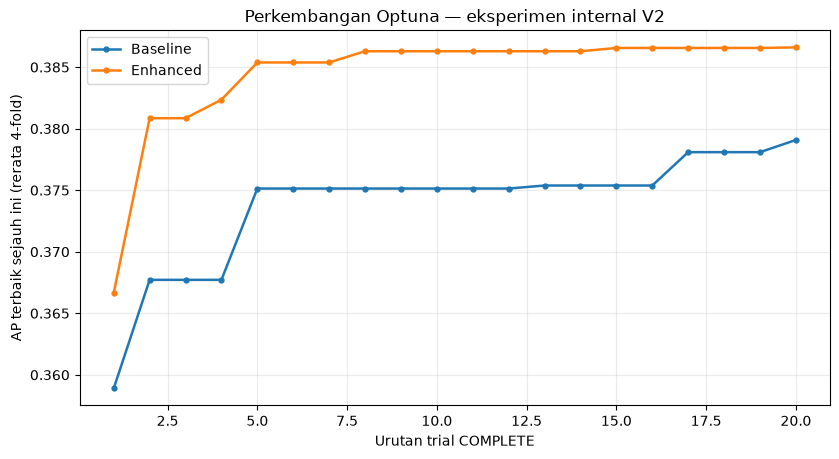

Gambar 300 dpi tersimpan: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Audit_Lanjutan_AP_V2\Gambar_Eksperimen_V2_1_Kurva_Best_AP_Optuna.png


In [34]:
try:
    import optuna
except ImportError:
    optuna = None

TRIAL_DIR_AUDIT_V2 = OUTPUT_AUDIT_SOURCE_V2 / "Optuna"

def read_trials_audit_v2(scenario):
    sqlite_path = TRIAL_DIR_AUDIT_V2 / f"Optuna_V2_{scenario}.sqlite3"
    csv_path = TRIAL_DIR_AUDIT_V2 / f"Optuna_V2_{scenario}_Trials.csv"
    if sqlite_path.is_file() and optuna is not None:
        study = optuna.load_study(
            study_name=f"ATL_2024_V2_{scenario}",
            storage="sqlite:///" + sqlite_path.resolve().as_posix()
        )
        assert study.direction.name == "MAXIMIZE"
        rows = []
        for trial in study.get_trials(deepcopy=False):
            d = {"number":int(trial.number), "value":trial.value,
                 "state":trial.state.name}
            for i in range(1, 5):
                d[f"ap_fold_{i}"] = trial.user_attrs.get(f"ap_fold_{i}", np.nan)
            rows.append(d)
        return pd.DataFrame(rows), "SQLite (riwayat Optuna)"
    if csv_path.is_file():
        t = pd.read_csv(csv_path)
        needed = {"number", "value", "state"}
        if not needed.issubset(t.columns):
            raise ValueError(f"CSV {scenario} tidak memuat {sorted(needed)}")
        keep = ["number", "value", "state"]
        for i in range(1, 5):
            name = f"user_attrs_ap_fold_{i}"
            if name in t.columns:
                t = t.rename(columns={name:f"ap_fold_{i}"})
                keep.append(f"ap_fold_{i}")
        return t[keep].copy(), "CSV (riwayat trial)"
    return None, "Tidak ditemukan"

TRIALS_AUDIT_V2 = {}
TRIALS_SOURCE_AUDIT_V2 = {}
TRIAL_SUMMARY_AUDIT_V2 = []
for scenario, expected_ap in [("Baseline", AP_MEAN_BASE_V2),
                              ("Enhanced", AP_MEAN_ENH_V2)]:
    trials, source_name = read_trials_audit_v2(scenario)
    TRIALS_SOURCE_AUDIT_V2[scenario] = source_name
    if trials is None:
        warnings.warn(
            f"Riwayat Optuna {scenario} tidak ditemukan. AP per fold dan "
            "bootstrap tetap valid sebagai hitungan dari file OOF, "
            "tetapi audit jumlah trial belum lengkap."
        )
        continue
    complete = trials.loc[trials["state"].astype(str).str.upper().eq("COMPLETE")].copy()
    failed = int(trials["state"].astype(str).str.upper().eq("FAIL").sum())
    complete["number"] = pd.to_numeric(complete["number"], errors="raise").astype(int)
    complete["value"] = pd.to_numeric(complete["value"], errors="raise")
    complete = complete.sort_values("number").reset_index(drop=True)
    assert complete["number"].is_unique
    assert complete["value"].notna().all() and complete["value"].between(0,1).all()
    assert len(complete) == EXPECTED_TRIALS_V2, (
        f"{scenario}: COMPLETE = {len(complete)}, seharusnya "
        f"{EXPECTED_TRIALS_V2}. Periksa proses optimasi asli."
    )
    for i in range(1,5):
        if f"ap_fold_{i}" not in complete.columns:
            break
    else:
        fold_trial = complete[[f"ap_fold_{i}" for i in range(1,5)]].apply(
            pd.to_numeric, errors="coerce")
        assert fold_trial.notna().all().all(), (
            f"{scenario}: sebagian atribut AP per fold dari trial tidak tersedia."
        )
        assert np.allclose(fold_trial.mean(axis=1).to_numpy(),
                           complete["value"].to_numpy(), atol=1e-8, rtol=0)
    best_value = float(complete["value"].max())
    assert np.isclose(best_value, expected_ap, atol=1e-8, rtol=0), (
        f"{scenario}: best Optuna={best_value:.10f} tidak cocok "
        f"dengan AP OOF per fold={expected_ap:.10f}."
    )
    complete["best_so_far"] = complete["value"].cummax()
    best_trial_no = int(complete.loc[complete["value"].idxmax(), "number"])
    last_improvement_at = int(complete.loc[
        complete["best_so_far"].diff().fillna(np.inf).gt(1e-12), "number"
    ].max())
    complete["urutan_complete"] = np.arange(1, len(complete)+1)
    TRIALS_AUDIT_V2[scenario] = complete
    TRIAL_SUMMARY_AUDIT_V2.append({
        "Skenario":scenario, "Sumber":source_name, "Trial COMPLETE":len(complete),
        "Trial FAIL":failed, "Best AP":best_value,
        "Nomor trial terbaik":best_trial_no,
        "Perbaikan terakhir pada trial":last_improvement_at,
    })

if TRIAL_SUMMARY_AUDIT_V2:
    # Output ringkas, bukan tabel tambahan untuk skripsi.
    print("RINGKASAN AUDIT OPTUNA V2 (tidak menjalankan trial baru)")
    for row in TRIAL_SUMMARY_AUDIT_V2:
        print(f"- {row['Skenario']}: COMPLETE={row['Trial COMPLETE']}, "
              f"FAIL={row['Trial FAIL']}, best AP={row['Best AP']:.6f}, "
              f"trial terbaik #{row['Nomor trial terbaik']}, "
              f"sumber={row['Sumber']}")

if len(TRIALS_AUDIT_V2) == 2:
    print("Gambar Eksperimen V2.1 Perkembangan Best Average Precision pada Trial Optuna")
    fig, ax = plt.subplots(figsize=(8.5, 4.7))
    for scenario in ("Baseline", "Enhanced"):
        history = TRIALS_AUDIT_V2[scenario]
        ax.plot(history["urutan_complete"], history["best_so_far"],
                marker="o", markersize=3.5, linewidth=1.8, label=scenario)
    ax.set_xlabel("Urutan trial COMPLETE")
    ax.set_ylabel("AP terbaik sejauh ini (rerata 4-fold)")
    ax.set_title("Perkembangan Optuna — eksperimen internal V2")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    image_optuna_v2 = AUDIT_DIR_V2 / "Gambar_Eksperimen_V2_1_Kurva_Best_AP_Optuna.png"
    fig.savefig(image_optuna_v2, dpi=300, bbox_inches="tight")
    plt.show()
    print("Gambar 300 dpi tersimpan:", image_optuna_v2.resolve())
else:
    print("Kurva Optuna belum dibuat karena kedua riwayat trial belum lengkap tersedia.")

### Audit metadata, arsip, dan interpretasi berbasis angka aktual
Periksa metadata V2 jika tersedia; hasilkan laporan ringkas yang tidak menyatakan perbedaan kecil sebagai bukti peningkatan generalisasi. Simpan seluruh keluaran ke folder audit baru. Tidak mengubah Tabel V2.2 atau V1.

In [35]:
METADATA_PATH_AUDIT_V2 = OUTPUT_AUDIT_SOURCE_V2 / "Metadata_Eksperimen_V2_2024.json"
META_CHECK_AUDIT_V2 = "Belum tersedia"
if METADATA_PATH_AUDIT_V2.is_file():
    metadata_audit_v2 = json.loads(METADATA_PATH_AUDIT_V2.read_text(encoding="utf-8"))
    assert int(metadata_audit_v2["n_development"]) == 223_971
    assert list(metadata_audit_v2["fold_months"]) == [5,6,7,8]
    assert int(metadata_audit_v2["n_trials_per_scenario"]) == EXPECTED_TRIALS_V2
    assert metadata_audit_v2["status"] == "EXPLORATORY_V2_NO_BLIND_TEST"
    for s, calculated in [("Baseline", AP_MEAN_BASE_V2),
                          ("Enhanced", AP_MEAN_ENH_V2)]:
        stored_ap = float(metadata_audit_v2["results"][s]["ap_fold_mean"])
        assert np.isclose(stored_ap, calculated, atol=1e-8, rtol=0), (
            f"Metadata AP {s} berbeda dari CSV prediksi OOF."
        )
    META_CHECK_AUDIT_V2 = "Lulus"
    print("Audit metadata V2: lulus (periode, fold, trial, dan AP sesuai).")
else:
    print("Metadata V2 belum ditemukan; hasil OOF dihitung, namun audit metadata belum lengkap.")

# Hanya statistik deskriptif: empat fold adalah dasar pemilihan hiperparameter.
positive_folds_v2 = int(TABLE_FOLD_V2["Selisih AP (pp)"].gt(0).sum())
primary_ci_v2 = TABLE_BOOT_V2.iloc[0]
ci_contains_zero_v2 = primary_ci_v2["CI mencakup nol"] == "Ya"
print("\nINTERPRETASI SEMENTARA AUDIT V2")
print(f"1. Enhanced unggul pada {positive_folds_v2}/4 fold temporal internal.")
print(f"2. Selisih rerata AP empat fold: "
      f"{100*(AP_MEAN_ENH_V2-AP_MEAN_BASE_V2):+.4f} poin persentase.")
print(f"3. Bootstrap blok tanggal (kondisional): CI 95% selisih AP rerata "
      f"[{primary_ci_v2['CI 95% bawah (pp)']:+.4f}, "
      f"{primary_ci_v2['CI 95% atas (pp)']:+.4f}] pp.")
if ci_contains_zero_v2:
    print("4. Interval mencakup nol: keunggulan pada data internal belum stabil "
          "menurut estimasi bootstrap ini.")
else:
    print("4. Interval tidak mencakup nol: hasil konsisten dengan selisih "
          "non-nol pada prediksi OOF, tetapi tetap optimistis karena "
          "pemilihan hiperparameter menggunakan fold yang sama.")
print("5. Keputusan untuk V1 dan testing 2024 TIDAK diubah oleh audit ini.")

for scenario, path in OOF_PATHS_AUDIT_V2.items():
    assert path.is_file()
assert csv_fold_v2.is_file() and html_fold_v2.is_file()
assert csv_ci_v2.is_file() and html_ci_v2.is_file()
assert csv_draws_v2.is_file()

def file_sha256_audit_v2(file_path):
    digest = hashlib.sha256()
    with open(file_path, "rb") as handle:
        for block in iter(lambda:handle.read(1024*1024), b""):
            digest.update(block)
    return digest.hexdigest()

summary_audit_v2 = {
    "analysis_status": "EXPLORATORY_V2_INTERNAL_VALIDATION_ONLY",
    "development_validation_period": "2024-05-01..2024-08-31",
    "n_oof": len(OOF_PAIRED_AUDIT_V2),
    "n_positive_folds_enhanced": positive_folds_v2,
    "ap_mean_4_fold": {"baseline": AP_MEAN_BASE_V2, "enhanced":AP_MEAN_ENH_V2},
    "ap_pooled_oof": {"baseline":AP_POOLED_BASE_V2, "enhanced":AP_POOLED_ENH_V2},
    "bootstrap_reps": BOOTSTRAP_REPS_V2,
    "bootstrap_seed": RANDOM_SEED_AUDIT_V2,
    "bootstrap_ci_conditional": TABLE_BOOT_V2.to_dict("records"),
    "bootstrap_limitation": "Conditional on hyperparameters selected from the same folds; not independent test uncertainty.",
    "optuna_sources": TRIALS_SOURCE_AUDIT_V2,
    "optuna_summary": TRIAL_SUMMARY_AUDIT_V2,
    "metadata_audit": META_CHECK_AUDIT_V2,
    "source_oof_sha256": {s:file_sha256_audit_v2(path)
                          for s,path in OOF_PATHS_AUDIT_V2.items()},
    "no_test_data_used": True,
    "no_fit_or_retuning": True,
}
json_audit_v2 = AUDIT_DIR_V2 / "Ringkasan_Audit_Lanjutan_AP_V2.json"
json_audit_v2.write_text(json.dumps(summary_audit_v2, ensure_ascii=False, indent=2),
                        encoding="utf-8")
assert json_audit_v2.is_file()
print("\nAudit tersimpan di:", AUDIT_DIR_V2.resolve())
print("Audit selesai. Lanjutkan interpretasi hanya berdasarkan tabel dan output aktual.")

Audit metadata V2: lulus (periode, fold, trial, dan AP sesuai).

INTERPRETASI SEMENTARA AUDIT V2
1. Enhanced unggul pada 2/4 fold temporal internal.
2. Selisih rerata AP empat fold: +0.7524 poin persentase.
3. Bootstrap blok tanggal (kondisional): CI 95% selisih AP rerata [-1.2426, +2.3339] pp.
4. Interval mencakup nol: keunggulan pada data internal belum stabil menurut estimasi bootstrap ini.
5. Keputusan untuk V1 dan testing 2024 TIDAK diubah oleh audit ini.

Audit tersimpan di: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semester 7 - SI\Skripsi\output_eksperimen_v2_2024\Audit_Lanjutan_AP_V2
Audit selesai. Lanjutkan interpretasi hanya berdasarkan tabel dan output aktual.


### Penilaian kesiapan V2 dan rekomendasi tindak lanjut

In [39]:
from html import escape as html_escape

required_vars_decision_v2 = [
    "TABLE_FOLD_V2", "TABLE_BOOT_V2", "TRIALS_AUDIT_V2",
    "TRIAL_SUMMARY_AUDIT_V2", "AUDIT_DIR_V2", "AP_MEAN_BASE_V2",
    "AP_MEAN_ENH_V2", "AP_POOLED_BASE_V2", "AP_POOLED_ENH_V2",
]
missing_vars_decision_v2 = [n for n in required_vars_decision_v2 if n not in globals()]
if missing_vars_decision_v2:
    raise RuntimeError("Jalankan seluruh sel audit V2 di atas terlebih dahulu. Objek belum ada: "
                       + ", ".join(missing_vars_decision_v2))

n_positive_v2 = int((TABLE_FOLD_V2["Selisih AP (pp)"] > 0).sum())
mean_delta_v2_pp = 100.0 * (AP_MEAN_ENH_V2 - AP_MEAN_BASE_V2)
pooled_delta_v2_pp = 100.0 * (AP_POOLED_ENH_V2 - AP_POOLED_BASE_V2)
ci_row_decision_v2 = TABLE_BOOT_V2.loc[
    TABLE_BOOT_V2["Ukuran"].str.contains("rerata 4-fold", case=False, regex=False)
]
if len(ci_row_decision_v2) != 1:
    raise AssertionError("Baris bootstrap untuk rerata AP empat fold tidak unik.")
ci_decision_v2 = ci_row_decision_v2.iloc[0]
ci_low_decision_v2 = float(ci_decision_v2["CI 95% bawah (pp)"])
ci_high_decision_v2 = float(ci_decision_v2["CI 95% atas (pp)"])

if mean_delta_v2_pp > 0:
    ap_finding_v2 = "Enhanced memiliki rerata AP internal lebih tinggi daripada Baseline."
elif mean_delta_v2_pp < 0:
    ap_finding_v2 = "Enhanced memiliki rerata AP internal lebih rendah daripada Baseline."
else:
    ap_finding_v2 = "Rerata AP internal kedua skenario sama."

if ci_low_decision_v2 > 0:
    ci_finding_v2 = ("Seluruh CI bootstrap kondisional berada di atas nol; hasil mendukung "
                     "selisih AP positif pada prediksi internal yang telah dipilih.")
elif ci_high_decision_v2 < 0:
    ci_finding_v2 = ("Seluruh CI bootstrap kondisional berada di bawah nol; "
                     "hasil mendukung selisih AP negatif pada prediksi internal.")
else:
    ci_finding_v2 = ("CI bootstrap kondisional mencakup nol; hasil belum mendukung "
                     "keunggulan yang stabil menurut prosedur ini.")

# Interpretasi Optuna bersifat diagnostik, tanpa tindakan optimize()/fit().
optuna_lines_decision_v2 = []
for scenario in ("Baseline", "Enhanced"):
    if scenario not in TRIALS_AUDIT_V2:
        optuna_lines_decision_v2.append(
            f"{scenario}: riwayat trial tidak tersedia; keputusan penambahan trial ditunda.")
        continue
    trials_v2 = TRIALS_AUDIT_V2[scenario].sort_values("urutan_complete")
    n_v2 = len(trials_v2)
    if n_v2 < 10:
        raise AssertionError(f"{scenario}: trial COMPLETE terlalu sedikit untuk audit tren.")
    best_final_v2 = float(trials_v2["best_so_far"].iloc[-1])
    best_before_five_v2 = float(trials_v2["best_so_far"].iloc[-6])
    gained_last_five_v2 = best_final_v2 - best_before_five_v2
    best_trial_order_v2 = int(trials_v2.loc[
        trials_v2["value"].idxmax(), "urutan_complete"])
    trend_v2 = (
        "masih ada kenaikan best AP pada lima trial terakhir; perluasan budget boleh dipertimbangkan "
        "jika komputer dan waktu memungkinkan"
        if gained_last_five_v2 > 1e-12 else
        "tidak ada kenaikan best AP pada lima trial terakhir; belum ada alasan kuat untuk menambah trial"
    )
    optuna_lines_decision_v2.append(
        f"{scenario}: {n_v2} trial COMPLETE; best AP={best_final_v2:.6f}; "
        f"trial terbaik urutan ke-{best_trial_order_v2}; "
        f"kenaikan best AP lima trial terakhir={gained_last_five_v2:+.6f}; {trend_v2}.")

if mean_delta_v2_pp > 0 and n_positive_v2 >= 3 and ci_low_decision_v2 > 0:
    decision_v2 = ("Layak didokumentasikan sebagai eksperimen tambahan dengan temuan positif "
                   "pada validasi internal, tetapi belum layak menggantikan evaluasi final V1.")
elif mean_delta_v2_pp > 0:
    decision_v2 = ("Layak didokumentasikan sebagai eksperimen tambahan eksploratif; "
                   "konsistensi/ketidakpastian belum cukup untuk klaim keunggulan yang kuat.")
else:
    decision_v2 = ("Belum ada alasan berdasarkan AP internal untuk memprioritaskan Enhanced V2; "
                   "laporkan hasil eksploratif dan pertahankan V1 sebagai hasil utama.")

report_lines_decision_v2 = [
    "# Ringkasan Keputusan Eksperimen V2 — ATL 2024",
    "",
    "**Status:** eksperimen pengembangan internal, bukan pengujian hold-out independen baru.",
    "",
    "## Hasil AP internal",
    f"- AP rerata empat fold: Baseline {AP_MEAN_BASE_V2:.6f}; Enhanced {AP_MEAN_ENH_V2:.6f}; selisih {mean_delta_v2_pp:+.4f} pp.",
    f"- AP OOF gabungan: Baseline {AP_POOLED_BASE_V2:.6f}; Enhanced {AP_POOLED_ENH_V2:.6f}; selisih {pooled_delta_v2_pp:+.4f} pp.",
    f"- Enhanced unggul pada {n_positive_v2} dari 4 fold temporal Mei–Agustus 2024.",
    f"- CI 95% bootstrap tanggal (selisih AP rerata): [{ci_low_decision_v2:+.4f}, {ci_high_decision_v2:+.4f}] pp.",
    f"- Interpretasi: {ap_finding_v2} {ci_finding_v2}",
    "",
    "## Riwayat Optuna",
] + [f"- {t}" for t in optuna_lines_decision_v2] + [
    "",
    "## Keputusan metodologis",
    f"- {decision_v2}",
    "- Jangan mengubah V1 atau memilih konfigurasi V2 berdasarkan hasil testing November–Desember 2024 yang sudah dilihat.",
    "- Bootstrap ini bersifat kondisional: fold yang sama sudah dipakai untuk memilih hiperparameter.",
    "- Kenaikan best AP pada beberapa trial terakhir hanyalah indikasi untuk meninjau anggaran optimasi, bukan bukti hasil akan meningkat.",
    "- Jika V2 masuk skripsi, jelaskan perubahan fitur dan desain fold dalam metodologi serta akui keterbatasan evaluasi pascahasil V1.",
    "- Lanjutkan SHAP dan sintesis V1 sambil berkonsultasi dengan dosen mengenai posisi eksperimen V2.",
    "",
    "## AP tiap fold",
    "",
    "| Fold | Validasi | Observasi | AP Baseline | AP Enhanced | Selisih (pp) |",
    "|---:|---|---:|---:|---:|---:|",
    *[f"| {int(r['Fold'])} | {r['Validasi']} | {int(r['Observasi']):,} | {r['AP Baseline']:.6f} | {r['AP Enhanced']:.6f} | {r['Selisih AP (pp)']:+.4f} |" for _, r in TABLE_FOLD_V2.iterrows()],
]
report_text_decision_v2 = "\n".join(report_lines_decision_v2) + "\n"
report_md_decision_v2 = AUDIT_DIR_V2 / "Ringkasan_Keputusan_V2_2024.md"
report_html_decision_v2 = AUDIT_DIR_V2 / "Ringkasan_Keputusan_V2_2024.html"
report_md_decision_v2.write_text(report_text_decision_v2, encoding="utf-8")

def html_list_decision_v2(lines):
    return "".join("<li>"+html_escape(x.lstrip("- "))+"</li>" for x in lines)

html_document_decision_v2 = f"""<!DOCTYPE html><html lang="id"><head><meta charset="utf-8">
<style>@page{{size:A4 portrait;margin:1.7cm}}body{{font:10pt Arial,Calibri,sans-serif;color:#111}}
h1{{font-size:14pt}}h2{{font-size:11pt;margin-top:18px}}table{{border-collapse:collapse;width:100%}}
th,td{{border:1px solid #999;padding:5px;overflow-wrap:break-word}}
th{{background:#eee}}.note{{font-size:9pt;color:#555}}</style></head><body>
<h1>Ringkasan Keputusan Eksperimen V2 — ATL 2024</h1>
<p class="note">Eksperimen pengembangan internal Mei–Agustus 2024; bukan evaluasi independen baru.</p>
<h2>Hasil AP</h2><ul>
<li>Rerata AP 4-fold: Baseline {AP_MEAN_BASE_V2:.6f}; Enhanced {AP_MEAN_ENH_V2:.6f}; Δ {mean_delta_v2_pp:+.4f} pp</li>
<li>AP OOF gabungan: Baseline {AP_POOLED_BASE_V2:.6f}; Enhanced {AP_POOLED_ENH_V2:.6f}; Δ {pooled_delta_v2_pp:+.4f} pp</li>
<li>Enhanced unggul pada {n_positive_v2} dari 4 fold</li>
<li>CI 95% bootstrap kondisional untuk Δ rerata AP: [{ci_low_decision_v2:+.4f}, {ci_high_decision_v2:+.4f}] pp</li></ul>
<p>{html_escape(ap_finding_v2)} {html_escape(ci_finding_v2)}</p>
<h2>AP per Fold</h2>{TABLE_FOLD_V2.to_html(index=False,border=0,float_format=lambda x:f"{x:.6f}")}
<h2>Riwayat Optuna</h2><ul>{html_list_decision_v2(optuna_lines_decision_v2)}</ul>
<h2>Rekomendasi</h2><p>{html_escape(decision_v2)}</p>
<p class="note">Perlu dicatat: hiperparameter dipilih pada fold yang sama sehingga selisih dan CI bersifat eksploratif. Data testing 2024 telah diketahui dalam eksperimen V1; jangan menyatakan evaluasi V2 pada periode tersebut sebagai blind hold-out baru.</p>
</body></html>"""
report_html_decision_v2.write_text(html_document_decision_v2, encoding="utf-8")
assert report_md_decision_v2.is_file() and report_html_decision_v2.is_file()

print("HASIL PENILAIAN KESIAPAN V2")
print(ap_finding_v2)
print(f"Enhanced unggul {n_positive_v2}/4 fold; CI rerata AP "
      f"[{ci_low_decision_v2:+.4f}, {ci_high_decision_v2:+.4f}] pp")
print(ci_finding_v2)
for line in optuna_lines_decision_v2:
    print("-", line)
print("Rekomendasi:", decision_v2)
print("Laporan Markdown:", report_md_decision_v2)
print("Laporan HTML Word:", report_html_decision_v2)

HASIL PENILAIAN KESIAPAN V2
Enhanced memiliki rerata AP internal lebih tinggi daripada Baseline.
Enhanced unggul 2/4 fold; CI rerata AP [-1.2426, +2.3339] pp
CI bootstrap kondisional mencakup nol; hasil belum mendukung keunggulan yang stabil menurut prosedur ini.
- Baseline: 20 trial COMPLETE; best AP=0.379080; trial terbaik urutan ke-20; kenaikan best AP lima trial terakhir=+0.003698; masih ada kenaikan best AP pada lima trial terakhir; perluasan budget boleh dipertimbangkan jika komputer dan waktu memungkinkan.
- Enhanced: 20 trial COMPLETE; best AP=0.386604; trial terbaik urutan ke-20; kenaikan best AP lima trial terakhir=+0.000047; masih ada kenaikan best AP pada lima trial terakhir; perluasan budget boleh dipertimbangkan jika komputer dan waktu memungkinkan.
Rekomendasi: Layak didokumentasikan sebagai eksperimen tambahan eksploratif; konsistensi/ketidakpastian belum cukup untuk klaim keunggulan yang kuat.
Laporan Markdown: C:\Users\Lenovo\OneDrive\Documents\UMN\UMN Lectures\Semest